<a href="https://colab.research.google.com/github/MarkowitzMx/Programacion-para-analitica-descriptiva-y-predictiva-2026/blob/main/Lemus_Cristobal_EDA_predictivoRespuestas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Cristóbal Lemus Rendón  

**Matrícula:** 274690

**Fecha:** 04/10/2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [ ]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Un contacto telefónico (una llamada) de la campaña de marketing directo del banco portugués a un cliente; cada fila del conjunto es un contacto (41,188 en total). |
| ¿Qué se predice? | Si el cliente contratará el depósito a plazo: la variable `y` (`yes` / `no`). |
| ¿Qué tipo de problema es? | Aprendizaje supervisado: clasificación binaria, con clases desbalanceadas (la clase `yes` es minoritaria). |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | Antes de llamar al cliente, para decidir a quién contactar. Existen los datos del cliente (edad, ocupación, estado civil, escolaridad, créditos), el historial de campañas anteriores (`pdays`, `previous`, `poutcome`) y el contexto económico vigente. No existe nada que ocurra durante o después de la llamada. |
| ¿Qué columnas no deberían usarse como características y por qué? | `duration`: es la duración de la llamada, solo se conoce una vez realizada, y llamadas largas son consecuencia de que el cliente muestra interés (fuga de información). También conviene revisar `campaign` (incluye el contacto actual, por lo que se conoce solo al terminar la campaña con ese cliente) y `month`/`day_of_week` (corresponden al último contacto, y el mes está ligado al momento del tiempo). |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del déposito? Escribe tu respeusta aquí, antes de ejecutar la celda de código.

Esperaba que alrededor del 10% de los contactos terminara en contratación. Mi razonamiento: en telemarketing bancario la gran mayoría de las llamadas termina en rechazo, así que la clase `yes` debía ser claramente minoritaria, entre el 8% y el 15%.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas encontrar `unknown` y en cuántas filas? Escribe aquí, antes de ejecutar la celda de código.

Esperaba que no hubiera ningún `NaN`, porque la pista indica que los faltantes se codifican con `unknown`. Esperaba `unknown` en `job`, `marital`, `education`, `default`, `housing` y `loan`; con pocas filas en `job` y `marital` (menos del 1%), algunos miles en `education` (alrededor del 4%) y la mayor cantidad en `default` (probablemente más del 15%), porque muchos clientes no declaran si tienen incumplimientos.

In [ ]:
# B1. Estructura del conjunto total
print("Dimensiones (filas, columnas):", df.shape)  # imprime el número de filas y de columnas de df
print("\nTipo de dato por columna:")  # encabezado de la sección de tipos de dato
print(df.dtypes)  # muestra el tipo de dato (texto, entero, decimal) de cada columna
print("\nValores únicos por columna (de menor a mayor):")  # encabezado de la sección de valores únicos
print(df.nunique().sort_values())  # cuenta valores distintos por columna y ordena ascendentemente

Dimensiones (filas, columnas): (41188, 21)

Tipo de dato por columna:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Valores únicos por columna (de menor a mayor):
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
job                 12


In [ ]:
# B2. Valores faltantes
print("Total de valores NaN en el conjunto:", df.isna().sum().sum())  # suma todos los NaN de todas las columnas
unknown = (df[categoricas] == "unknown").sum()  # cuenta las filas con "unknown" en cada columna categórica
unknown = unknown[unknown > 0]  # conserva solo las columnas con al menos un "unknown"
resumen_unknown = pd.DataFrame({  # arma una tabla resumen con el conteo y el porcentaje
    "filas_unknown": unknown,  # número de filas con "unknown" por columna
    "porcentaje": (unknown / len(df) * 100).round(2)  # ese conteo como porcentaje del total de filas
})  # cierra la construcción de la tabla
print(resumen_unknown)  # muestra la tabla de faltantes codificados como "unknown"

Total de valores NaN en el conjunto: 0
           filas_unknown  porcentaje
job                  330        0.80
marital               80        0.19
education           1731        4.20
default             8597       20.87
housing              990        2.40
loan                 990        2.40


In [ ]:
# B3. Duplicados
print("Filas completamente idénticas:", df.duplicated().sum())  # cuenta las filas que repiten por completo a otra anterior

Filas completamente idénticas: 12


In [ ]:
# B4. Consistencia entre columnas relacionadas
n_999 = (df["pdays"] == 999).sum()  # número de filas con el código especial 999 en pdays
print("Filas con pdays == 999:", n_999, f"({n_999 / len(df) * 100:.2f}%)")  # lo imprime con su porcentaje
print("\npoutcome vs (previous == 0):")  # encabezado de la primera tabla de contingencia
print(pd.crosstab(df["poutcome"], df["previous"] == 0))  # cruza el resultado previo con "sin contactos previos"
print("\npoutcome vs (pdays == 999):")  # encabezado de la segunda tabla de contingencia
print(pd.crosstab(df["poutcome"], df["pdays"] == 999))  # cruza el resultado previo con "no contactado antes"

Filas con pdays == 999: 39673 (96.32%)

poutcome vs (previous == 0):
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

poutcome vs (pdays == 999):
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [ ]:
# B5. Rangos según el dominio
print("Edad mínima y máxima:", df["age"].min(), df["age"].max())  # rango de edades observado
print("Llamadas con duration == 0:", (df["duration"] == 0).sum())  # llamadas de cero segundos
print("campaign mínimo y máximo:", df["campaign"].min(), df["campaign"].max())  # rango del número de contactos
print("Filas con previous negativo:", (df["previous"] < 0).sum())  # contactos previos imposibles (negativos)

Edad mínima y máxima: 17 98
Llamadas con duration == 0: 4
campaign mínimo y máximo: 1 56
Filas con previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable. Escribe tu respuesta aquí y compárala con tu predicción.

Resultados del código frente a mi predicción:

- **`NaN`: 0.** Coincide con mi predicción; no hay nulos en sentido estricto.
- **`unknown`:** `default` 8,597 filas (20.87%), `education` 1,731 (4.20%), `housing` y `loan` 990 cada una (2.40%), `job` 330 (0.80%) y `marital` 80 (0.19%). Acerté en las columnas y en el orden de magnitud; `default` es, por mucho, la más afectada. `housing` y `loan` tienen exactamente 990 porque los faltantes se dan en las mismas filas.
- **Duplicados:** 12 filas completamente idénticas (insignificante, 0.03%).
- **Código especial `pdays == 999`:** 39,673 filas (96.32%). No es un número de días real sino "no contactado antes"; tratarlo como numérico distorsionaría la variable. *Depende del significado de la variable.*
- **Consistencia entre columnas:** `poutcome = nonexistent` ocurre en las 35,563 filas con `previous == 0` y en las 35,563 con `pdays == 999`, sin excepciones. Pero hay 4,110 filas con `poutcome = failure` y `pdays == 999` aun con `previous > 0`: clientes contactados antes cuyo `pdays` no quedó registrado. Es una inconsistencia que depende del significado. Además `poutcome` y `previous` son redundantes en parte.
- **Rangos:** edad entre 17 y 98 años (plausible); `duration == 0` en 4 llamadas (llamadas sin duración, inútiles como información); `campaign` entre 1 y 56 (un valor de 56 contactos a una misma persona es extremo y sospechoso); 0 filas con `previous` negativo.
- **Calidad que depende del significado:** el 999 de `pdays`, los `unknown` (son faltantes disfrazados de categoría) y las llamadas de 0 segundos.

**Tu respuesta.** ¿Qué harias con  `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aqui.

 Trataría `unknown` en `default` **como una categoría más**, sin imputar ni eliminar filas. Razones, con lo observado:

1. **Eliminar filas** perdería 8,597 filas (20.87% del conjunto), una pérdida enorme y además sesgada.
2. **Imputar** (por ejemplo con la moda `no`) supondría que el cliente que no respondió es igual a quien respondió `no`, y los datos lo desmienten: en entrenamiento, la tasa de contratación con `unknown` es de 5.20% (6,940 clientes) frente a 12.88% de `no` (26,007 clientes). Imputar borraría esa señal.
3. El hecho de que no haya respuesta es en sí informativo (por ejemplo, depende del canal o del tipo de cliente), por lo que conservarlo como categoría explícita permite al modelo aprovecharlo. Además, `default = yes` casi no existe (solo 3 casos en entrenamiento), por lo que la variable es casi una indicadora de `unknown` vs `no`.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenaiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Esperaba que las proporciones fueran prácticamente iguales (alrededor del 11.3% en ambos conjuntos), porque la división es **estratificada** según `y`: la estratificación conserva la proporción de cada clase en cada subconjunto, con diferencias solo por redondeo.

In [ ]:
# C1. División en entrenamiento y prueba (80% / 20%), estratificada
entrenamiento, prueba = train_test_split(  # divide df en dos subconjuntos
    df,  # conjunto total que se divide
    test_size=0.2,  # 20% para prueba y 80% para entrenamiento
    stratify=df["y"],  # conserva la proporción de yes/no en ambos subconjuntos
    random_state=42  # semilla fija para que el resultado sea reproducible
)  # cierra la llamada a train_test_split
ent = entrenamiento.copy()  # copia de entrenamiento sobre la que se trabajará
ent["suscribe"] = (ent["y"] == "yes").astype(int)  # variable objetivo numérica: 1 si yes, 0 si no
print("Tamaño de entrenamiento:", entrenamiento.shape[0])  # número de filas de entrenamiento
print("Tamaño de prueba:", prueba.shape[0])  # número de filas de prueba
print(f"% de contratación en entrenamiento: {(entrenamiento['y'] == 'yes').mean() * 100:.3f}%")  # tasa de yes en entrenamiento
print(f"% de contratación en prueba: {(prueba['y'] == 'yes').mean() * 100:.3f}%")  # tasa de yes en prueba

Tamaño de entrenamiento: 32950
Tamaño de prueba: 8238
% de contratación en entrenamiento: 11.266%
% de contratación en prueba: 11.265%


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [ ]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y comparala con tu predicción.

La proporción de contratación es de 11.266% en entrenamiento (32,950 filas) y de 11.265% en prueba (8,238 filas): prácticamente idénticas, como predije. La diferencia es de milésimas de punto porcentual, debida al redondeo, gracias a la estratificación. Con ello, la métrica del conjunto de prueba será comparable con lo que el modelo vea al entrenar. La verificación proporcionada confirma que la división cumple las especificaciones.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera simpre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Un modelo que responda siempre `no` tendría una exactitud de alrededor del 89% (1 menos la tasa de contratación de ~11%). Es decir, una exactitud muy alta sin haber aprendido nada.

Número de clientes por clase:
 y
no     29238
yes     3712
Name: count, dtype: int64

Porcentaje por clase:
 y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Razón mayoritaria/minoritaria: 7.88 a 1
Exactitud de responder siempre 'no': 88.73%


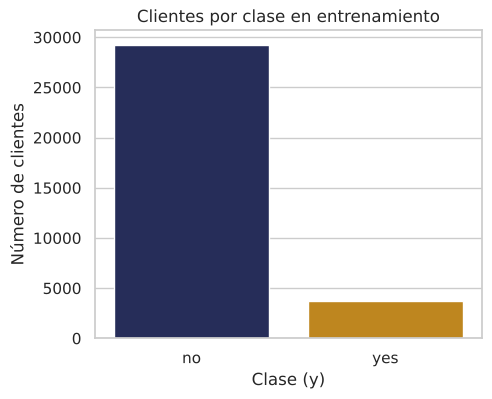

In [ ]:
# D1. Distribución de la variable objetivo en entrenamiento
conteo = ent["y"].value_counts()  # número de clientes por clase
porcentaje = ent["y"].value_counts(normalize=True) * 100  # porcentaje de clientes por clase
print("Número de clientes por clase:\n", conteo)  # imprime los conteos
print("\nPorcentaje por clase:\n", porcentaje.round(2))  # imprime los porcentajes redondeados
razon = conteo.max() / conteo.min()  # razón entre la clase mayoritaria y la minoritaria
print(f"\nRazón mayoritaria/minoritaria: {razon:.2f} a 1")  # imprime la razón de desbalance
exactitud_no = (ent["y"] == "no").mean()  # exactitud de un modelo que siempre responde "no"
print(f"Exactitud de responder siempre 'no': {exactitud_no * 100:.2f}%")  # la imprime en porcentaje
fig, ax = plt.subplots(figsize=(5, 4))  # crea la figura y el eje
sns.barplot(x=conteo.index, y=conteo.values, palette=COLORES_CLASE, hue=conteo.index, legend=False, ax=ax)  # barras por clase con los colores definidos
ax.set_xlabel("Clase (y)")  # etiqueta del eje horizontal
ax.set_ylabel("Número de clientes")  # etiqueta del eje vertical
ax.set_title("Clientes por clase en entrenamiento")  # título de la gráfica
plt.show()  # muestra la gráfica

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción.

En entrenamiento hay 29,238 clientes `no` (88.73%) y 3,712 `yes` (11.27%): una razón de 7.88 a 1. Responder siempre `no` da una exactitud de 88.73%, casi igual a mi predicción (89%) y coincide con mi estimación de la parte A (~10-11%).

**Implicación para la evaluación:** la exactitud (*accuracy*) es engañosa; un modelo inútil obtendría 88.73%, así que cualquier modelo debe superar ese piso para tener valor. Hay que evaluar con métricas sensibles a la clase minoritaria (recall, precisión, F1, AUC-ROC y sobre todo AUC-PR), usar validación cruzada estratificada y considerar técnicas de balanceo (pesos de clase, remuestreo) o ajustar el umbral de decisión.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ‚Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu resuesta aquí, antes de ejecutar la celda de código.

Esperaba que `duration` difiriera mucho (llamadas más largas implican más interés) y que los indicadores económicos (`euribor3m`, `emp.var.rate`, `nr.employed`) también difirieran, porque con tasas bajas los depósitos a plazo son más atractivos para el cliente. Esperaba que `age` y `campaign` difirieran poco.

y                     no       yes
age               38.000    37.000
duration         164.000   448.000
campaign           2.000     2.000
pdays            999.000   999.000
previous           0.000     0.000
emp.var.rate       1.100    -1.800
cons.price.idx    93.918    93.200
cons.conf.idx    -41.800   -40.400
euribor3m          4.857     1.266
nr.employed     5195.800  5099.100


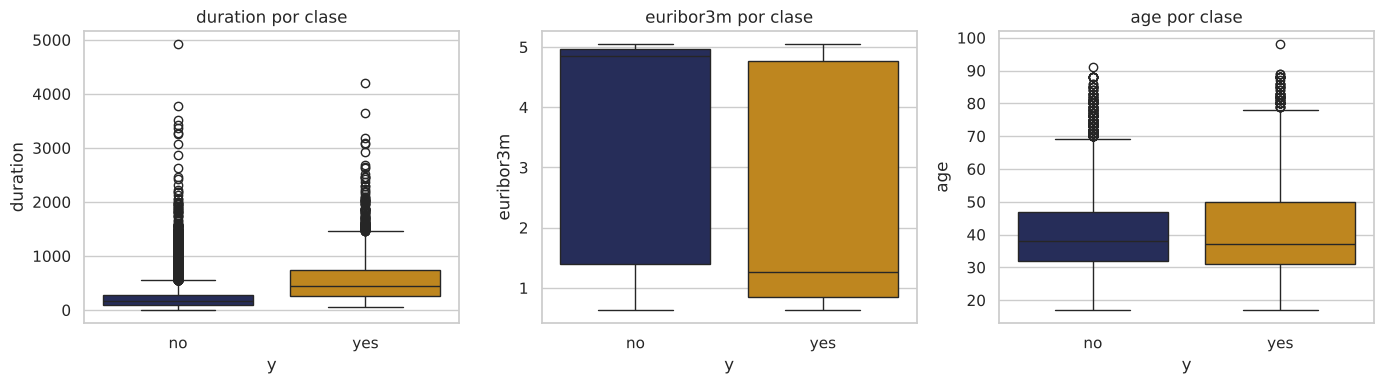

In [ ]:
# D2. Variables numéricas según la clase
print(ent.groupby("y")[numericas].median().T)  # mediana de cada variable numérica por clase, transpuesta para leerla mejor
elegidas = ["duration", "euribor3m", "age"]  # tres variables numéricas para los diagramas de caja
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))  # una fila con tres paneles
for ax, var in zip(ejes, elegidas):  # recorre cada eje junto con su variable
    sns.boxplot(data=ent, x="y", y=var, palette=COLORES_CLASE, hue="y", legend=False, order=["no", "yes"], ax=ax)  # diagrama de caja por clase
    ax.set_title(f"{var} por clase")  # título del panel con el nombre de la variable
plt.tight_layout()  # ajusta el espaciado entre paneles
plt.show()  # muestra la figura

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción.

 Medianas por clase (`no` / `yes`):

- **Separan bien:** `duration` (164 s vs 448 s: casi el triple), `euribor3m` (4.857 vs 1.266), `emp.var.rate` (1.1 vs -1.8) y `nr.employed` (5,195.8 vs 5,099.1). Quienes contratan son contactados en un contexto de tasas bajas y empleo en descenso.
- **Separan poco:** `age` (38 vs 37), `campaign` (2 vs 2), `cons.price.idx` (93.918 vs 93.200) y `cons.conf.idx` (-41.8 vs -40.4).
- **No informativas por la mediana:** `pdays` (999 en ambas) y `previous` (0 en ambas), porque la mayoría no tenía contacto previo. Su mediana no refleja la diferencia real; hay que analizarlas con `poutcome`.

Mi predicción fue acertada para `duration` y los indicadores económicos, y también para `age` y `campaign`. `duration` es una variable no utilizable (ver parte F2), por lo que el poder predictivo real viene del contexto económico.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí.

Esperaba más atípicos en `duration` y `campaign` (distribuciones con cola derecha larga) y también en `previous`, `pdays` y `age`. Esperaba pocos o ninguno en los indicadores económicos.

In [ ]:
# D3. Límites de Tukey y atípicos, calculados con ent
q1 = ent[numericas].quantile(0.25)  # primer cuartil de cada variable numérica
q3 = ent[numericas].quantile(0.75)  # tercer cuartil de cada variable numérica
rango_iq = q3 - q1  # rango intercuartílico (RIC)
limite_inf = q1 - 1.5 * rango_iq  # límite inferior de Tukey
limite_sup = q3 + 1.5 * rango_iq  # límite superior de Tukey
fuera = {}  # diccionario para guardar los conteos
for var in numericas:  # recorre cada variable numérica
    fuera[var] = ((ent[var] < limite_inf[var]) | (ent[var] > limite_sup[var])).sum()  # cuenta registros fuera de los límites
tabla_tukey = pd.DataFrame({  # arma la tabla resumen
    "limite_inf": limite_inf,  # límites inferiores
    "limite_sup": limite_sup,  # límites superiores
    "registros_fuera": pd.Series(fuera)  # número de atípicos por variable
})  # cierra la tabla
print(tabla_tukey)  # muestra la tabla de límites y atípicos

                limite_inf  limite_sup  registros_fuera
age                 9.5000     69.5000              368
duration         -221.0000    643.0000             2366
campaign           -2.0000      6.0000             1916
pdays             999.0000    999.0000             1226
previous            0.0000      0.0000             4534
emp.var.rate       -6.6000      6.2000                0
cons.price.idx     91.6965     95.3725                0
cons.conf.idx     -52.1500    -26.9500              359
euribor3m          -4.0815     10.3865                0
nr.employed      4905.6000   5421.6000                0


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

Resultados (registros fuera de Tukey en entrenamiento): `previous` 4,534; `duration` 2,366; `campaign` 1,916; `pdays` 1,226; `age` 368; `cons.conf.idx` 359; y 0 en `emp.var.rate`, `cons.price.idx`, `euribor3m` y `nr.employed`. Coincide con mi predicción, salvo en que `cons.conf.idx` también tiene algunos.

**No eliminaría los registros atípicos de ninguna variable**, y lo justifico por variable:

- `age` (368, mayores de 69.5 años): son personas reales (jubilados), y los jubilados tienen una tasa de contratación alta (25.48%); eliminarlos quitaría un segmento relevante.
- `duration` (2,366): variable que no se usará como característica, así que no se trata.
- `campaign` (1,916, más de 6 contactos): son clientes realmente muy contactados. Es una cola larga legítima; para modelos sensibles a escala basta con una transformación (log) o un tope (*winsorizing*).
- `pdays` y `previous` (1,226 y 4,534): los límites de Tukey no tienen sentido aquí; con más del 96% de los valores en 999 y en 0 el RIC es cero y cualquier valor distinto parece atípico. Son precisamente los clientes con historial, que son los más valiosos (`poutcome = success` tiene 64.89%).
- `cons.conf.idx` (359): son valores de un indicador económico mensual; son reales y repetidos, no errores.

Para modelos de árbol no hay que hacer nada; para modelos lineales, SVM o redes se resuelve con transformación y escalamiento, no con eliminación.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.**  ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Esperaba que el logaritmo (`np.log1p`) redujera más la asimetría de `campaign` que la raíz cuadrada, porque la raíz comprime menos las colas largas y `campaign` tiene una cola derecha muy marcada.

          original  raiz_cuadrada  log1p
age          0.761          0.426  0.132
duration     3.327          1.204 -0.430
campaign     4.743          2.163  1.351


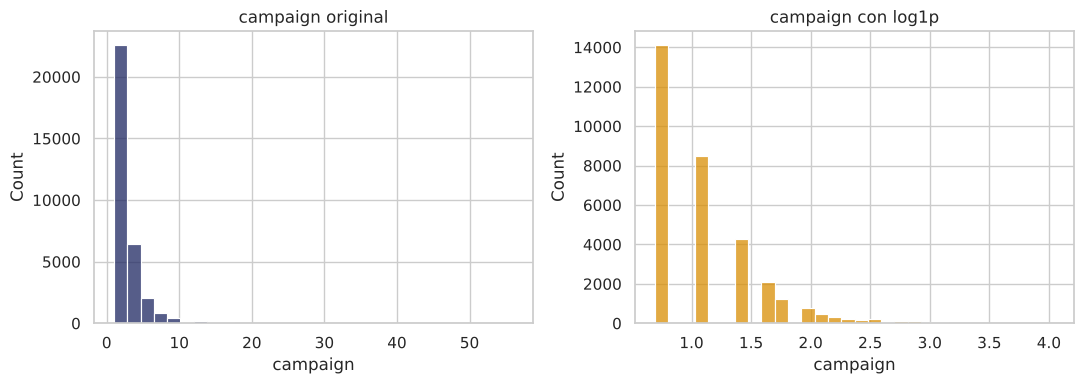

In [ ]:
# D4. Asimetría original y transformada, con ent
variables = ["age", "duration", "campaign"]  # variables a revisar
asimetria = pd.DataFrame({  # arma la tabla comparativa de asimetrías
    "original": ent[variables].skew(),  # asimetría de los datos originales
    "raiz_cuadrada": np.sqrt(ent[variables]).skew(),  # asimetría tras la raíz cuadrada
    "log1p": np.log1p(ent[variables]).skew()  # asimetría tras el logaritmo log(1 + x)
})  # cierra la tabla
print(asimetria.round(3))  # muestra la tabla con tres decimales
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))  # dos paneles: original y transformada
sns.histplot(ent["campaign"], bins=30, color=AZUL, ax=ejes[0])  # histograma de campaign original
ejes[0].set_title("campaign original")  # título del primer panel
sns.histplot(np.log1p(ent["campaign"]), bins=30, color=NARANJA, ax=ejes[1])  # histograma de campaign con log1p
ejes[1].set_title("campaign con log1p")  # título del segundo panel
plt.tight_layout()  # ajusta el espaciado
plt.show()  # muestra la figura

**Tu observación.** Reporta las asimetrias y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

Asimetrías en entrenamiento (original / raíz / log1p):

| Variable | Original | Raíz cuadrada | log1p |
| --- | --- | --- | --- |
| `age` | 0.761 | 0.426 | 0.132 |
| `duration` | 3.327 | 1.204 | -0.430 |
| `campaign` | 4.743 | 2.163 | 1.351 |

Acerté: en `campaign`, el logaritmo reduce más la asimetría (4.74 a 1.35) que la raíz (2.16). **Decisión:** `campaign` con `log1p` para modelos sensibles a la escala (sigue algo asimétrica, así que además se puede topar); `age` tiene una asimetría moderada y mejora con `log1p` (0.13), pero no es necesaria, basta con escalarla; `duration` mejora con log1p pero se descarta como característica. Para árboles y conjuntos de árboles, ninguna transformación es necesaria.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Esperaba las mayores tasas en `poutcome = success` (quien contrató antes vuelve a contratar) y en algunos meses; también en `job` (estudiantes y jubilados). Esperaba que `day_of_week`, `housing` y `loan` casi no separaran las clases.

In [ ]:
# E1. Número de categorías y tasa global
print("Categorías por variable:")  # encabezado
print(ent[categoricas].nunique())  # cuenta categorías distintas de cada variable categórica
tasa_global = ent["suscribe"].mean() * 100  # tasa global de contratación en porcentaje
print(f"\nTasa global de contratación en ent: {tasa_global:.2f}%")  # la imprime con dos decimales

Categorías por variable:
job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
dtype: int64

Tasa global de contratación en ent: 11.27%


In [ ]:
# E2. Clientes y tasa de contratación por categoría
largo = ent.melt(id_vars="suscribe", value_vars=categoricas, var_name="variable", value_name="categoria")  # pasa a formato largo: una fila por (cliente, variable)
tabla = largo.groupby(["variable", "categoria"]).agg(  # agrupa por variable y categoría
    clientes=("suscribe", "size"),  # número de clientes de la categoría
    tasa=("suscribe", "mean")  # proporción que contrató
).reset_index()  # devuelve los índices como columnas
tabla["tasa"] = (tabla["tasa"] * 100).round(2)  # convierte la tasa a porcentaje
print("12 categorías con mayor tasa:")  # encabezado
print(tabla.nlargest(12, "tasa").to_string(index=False))  # las 12 de mayor tasa
print("\n8 categorías con menor tasa:")  # encabezado
print(tabla.nsmallest(8, "tasa").to_string(index=False))  # las 8 de menor tasa
for var in ["default", "housing", "loan", "day_of_week"]:  # recorre las cuatro variables pedidas
    print(f"\n{var}:")  # nombre de la variable
    print(tabla[tabla["variable"] == var].sort_values("tasa", ascending=False).to_string(index=False))  # su tabla ordenada por tasa

12 categorías con mayor tasa:
 variable  categoria  clientes  tasa
 poutcome    success      1105 64.89
    month        dec       143 50.35
    month        mar       436 49.77
    month        sep       464 44.61
    month        oct       587 43.27
      job    student       711 30.52
      job    retired      1366 25.48
    month        apr      2085 20.48
education illiterate        16 18.75
  marital    unknown        65 16.92
education    unknown      1397 14.82
  contact   cellular     20908 14.70

8 categorías con menor tasa:
 variable   categoria  clientes  tasa
  default         yes         3  0.00
  default     unknown      6940  5.20
  contact   telephone     12042  5.30
    month         may     11011  6.35
      job blue-collar      7441  6.92
education    basic.9y      4826  7.65
      job    services      3196  7.95
education    basic.6y      1865  8.36

default:
variable categoria  clientes  tasa
 default        no     26007 12.88
 default   unknown      6940  5.20
 d

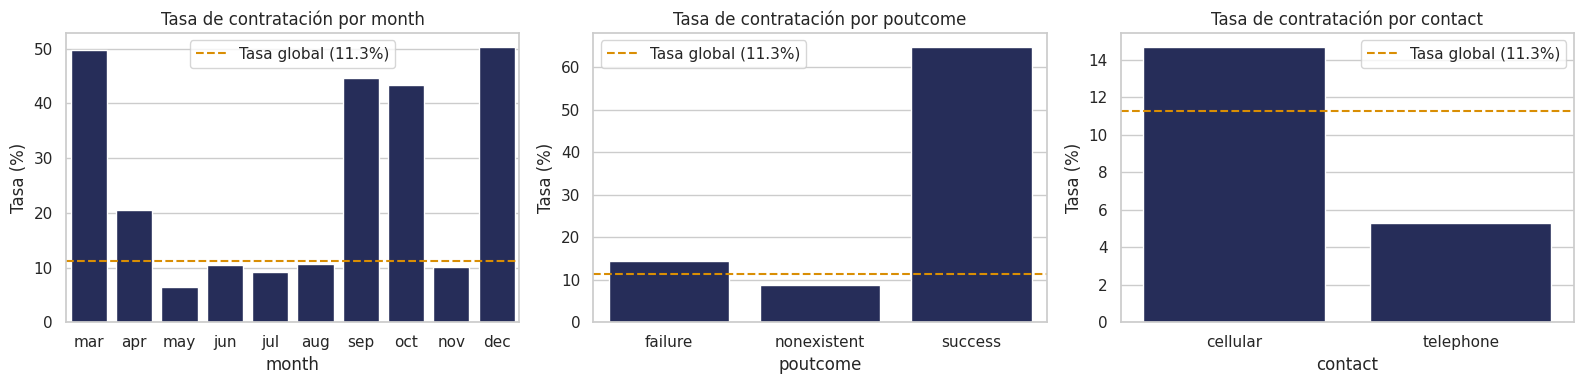

In [ ]:
# E3. Tasa de contratación por categoría de month, poutcome y contact
orden_mes = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]  # orden cronológico de los meses
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))  # tres paneles en una fila
for ax, var in zip(ejes, ["month", "poutcome", "contact"]):  # recorre cada variable con su eje
    tasas = ent.groupby(var)["suscribe"].mean() * 100  # tasa de contratación por categoría en porcentaje
    if var == "month":  # solo para el mes se aplica el orden cronológico
        tasas = tasas.reindex(orden_mes)  # reordena las categorías de mes
    sns.barplot(x=tasas.index, y=tasas.values, color=AZUL, ax=ax)  # barras con la tasa por categoría
    ax.axhline(tasa_global, color=NARANJA, linestyle="--", label=f"Tasa global ({tasa_global:.1f}%)")  # línea horizontal en la tasa global
    ax.set_title(f"Tasa de contratación por {var}")  # título del panel
    ax.set_ylabel("Tasa (%)")  # etiqueta del eje vertical
    ax.legend()  # muestra la leyenda de la línea
plt.tight_layout()  # ajusta el espaciado
plt.show()  # muestra la figura

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respueta auí y compárala con tu predicción.

Tasa global: 11.27%.

- **Mayores tasas:** `poutcome = success` 64.89% (1,105 clientes); `month = dec` 50.35% (143) y `mar` 49.77% (436); `sep` 44.61% (464) y `oct` 43.27% (587); `job = student` 30.52% (711) y `retired` 25.48% (1,366); `apr` 20.48% (2,085); `education = illiterate` 18.75% (solo 16 clientes); `contact = cellular` 14.70% (20,908).
- **Menores tasas:** `default = yes` 0.00% (3 clientes), `default = unknown` 5.20% (6,940), `contact = telephone` 5.30% (12,042), `month = may` 6.35% (11,011), `job = blue-collar` 6.92% (7,441), `education = basic.9y` 7.65% (4,826), `job = services` 7.95% (3,196) y `education = basic.6y` 8.36% (1,865).
- **Casi no separan:** `day_of_week` (de 10.25% el lunes a 12.00% el jueves), `housing` (10.93% a 11.56%) y `loan` (11.23% a 11.27%). Mi predicción fue acertada: `poutcome` y el mes destacan, y `day_of_week`, `housing` y `loan` casi no aportan.
- Ojo con los meses de alta tasa (`dec`, `mar`, `sep`, `oct`): tienen pocos clientes (143 a 587) frente a `may` (11,011), así que sus tasas son menos confiables y reflejan el momento de la campaña.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown`tenga una tasa de contratación distinta a la de `no`?¿Qué hay que cuidar con las categorías `yes`de `default` o ` illiterate` de `education`? Escribe tu respuesta aquí.

En `default`, que `unknown` tenga una tasa distinta a la de `no` (5.20% con 6,940 clientes frente a 12.88% con 26,007) indica que **el faltante no es aleatorio**: no responder está asociado a un perfil distinto de cliente (posiblemente al medio de contacto o a la época de la campaña), así que es información y no un simple vacío. Por eso no conviene imputarlo ni borrarlo; se conserva como categoría.

**Cuidados con categorías muy pequeñas:** `default = yes` tiene 3 clientes (tasa 0.00%) e `education = illiterate` tiene 16 (18.75%). Con tan pocos registros, la tasa es inestable y poco confiable (una sola contratación cambia la tasa en más de 6 puntos en `illiterate`). Un modelo podría sobreajustar a estas categorías, y podrían quedar fuera de la muestra de prueba o de validación. Se deben agrupar con otra categoría afín (por ejemplo, `illiterate` con `basic.4y`, y `default = yes` con `unknown`) o fusionar en una categoría "otros" antes de codificar.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Esperaba una correlación muy alta entre `euribor3m`, `emp.var.rate` y `nr.employed`, porque los tres reflejan el mismo ciclo económico, y una correlación menor con `cons.conf.idx`.

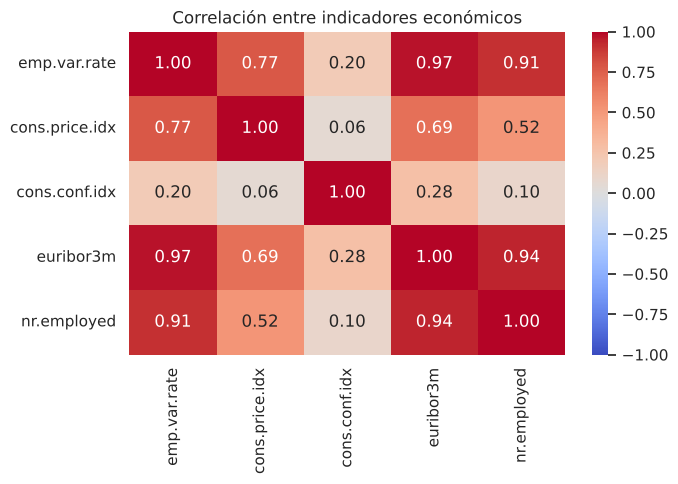

In [ ]:
# F1. Mapa de calor de correlación de los indicadores económicos, con ent
correlacion = ent[macro].corr()  # matriz de correlación de Pearson entre las variables de macro
plt.figure(figsize=(7, 5))  # crea la figura
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)  # mapa de calor con valores anotados en cada celda
plt.title("Correlación entre indicadores económicos")  # título de la gráfica
plt.tight_layout()  # ajusta márgenes
plt.show()  # muestra la figura

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

Los pares más correlacionados son `emp.var.rate`–`euribor3m` (0.97), `euribor3m`–`nr.employed` (0.94) y `emp.var.rate`–`nr.employed` (0.91); también `emp.var.rate`–`cons.price.idx` (0.77). `cons.conf.idx` es la menos relacionada con las demás (0.06 a 0.28). Mi predicción fue correcta.

**Decisión:** los tres indicadores del núcleo son prácticamente redundantes (colinealidad). Para modelos lineales conservaría solo uno (por ejemplo `euribor3m`) o aplicaría regularización/PCA; para árboles la redundancia no es un problema grave, pero sí diluye la importancia de las variables.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [ ]:
# F2. Resumen estadístico de duration por clase
print(ent.groupby("y")["duration"].describe())  # count, media, desviación, mínimo, cuartiles y máximo de duration por clase

       count        mean         std   min    25%    50%    75%     max
y                                                                      
no   29238.0  221.148198  208.303557   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.398976  397.490060  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ** ¿Incluirías `duration`como característica de un modelo que se usará para decidir a quén llamar? Justifica con la definición de la variable y lo observado. Escribe tu respeusta aquí.

No incluiría `duration`** en un modelo para decidir a quién llamar. Por definición, es la duración de la última llamada y solo se conoce después de hacerla, es decir, no existe en el momento en que se tiene que decidir a quién llamar: usarla sería fuga de información (*data leakage*).

Lo observado confirma que está muy relacionada con el objetivo: media de 549.4 s en `yes` frente a 221.1 s en `no` y mediana de 448 s frente a 164 s; el cuartil inferior de `yes` (252 s) supera a la mediana de `no`. Pero esa relación es una **consecuencia** de la contratación (quien está interesado habla más), no una causa utilizable. Un modelo con `duration` tendría un desempeño inflado e inútil en la práctica. Solo serviría para un modelo de referencia o para entender el fenómeno.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varian con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

Dividir al azar mezcla contactos de todas las fechas en entrenamiento y prueba, de modo que el modelo se entrena con información "del futuro" respecto de algunos contactos de prueba. Como los indicadores económicos varían con el tiempo y son casi constantes dentro de un mismo periodo, un contacto de prueba tiene "gemelos" temporales en entrenamiento (mismos valores económicos), y el modelo puede acertar solo por reconocer el periodo. Eso hace que la métrica sea **optimista** respecto de lo que ocurrirá en campañas futuras, cuyas condiciones económicas serán nuevas.

Para un modelo que se usará en campañas futuras, es más honesto dividir **por tiempo** (entrenar con los contactos más antiguos y evaluar con los más recientes) o usar validación cruzada de series de tiempo.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| `duration` se conoce solo tras la llamada; mediana 448 s en `yes` vs 164 s en `no` (media 549.4 vs 221.1) | **Variable no utilizable:** excluirla de las características (fuga de información) | Preprocesamiento / selección de características |
| `pdays == 999` en 39,673 filas (96.32%); es un código de "no contactado" | Reemplazar por un indicador `contactado_antes` (0/1) y, para quienes sí fueron contactados, conservar los días reales; no tratar el 999 como número | Preprocesamiento |
| `default = unknown` en 8,597 filas (20.87%); tasa 5.20% vs 12.88% de `no` | Mantener `unknown` como **categoría propia**, no imputar ni eliminar filas (y hacerlo también en `education`, 4.20%, `housing`/`loan`, 2.40%) | Preprocesamiento (codificación) |
| Desbalance: 88.73% `no` vs 11.27% `yes` (razón 7.88:1); responder siempre `no` da 88.73% de exactitud | No usar exactitud; evaluar con recall, F1, AUC-PR y AUC-ROC; validación cruzada estratificada; probar pesos de clase y ajuste de umbral | Evaluación y modelos |
| `euribor3m`–`emp.var.rate` 0.97, `euribor3m`–`nr.employed` 0.94, `emp.var.rate`–`nr.employed` 0.91 | Reducir redundancia: conservar un indicador (p. ej. `euribor3m`) o usar PCA/regularización en modelos lineales | Preprocesamiento / modelos lineales |
| Asimetría de `campaign` 4.74 (log1p: 1.35; raíz: 2.16); `age` 0.76 | Aplicar `log1p` a `campaign` en modelos sensibles a la escala; `age` solo escalar; árboles sin transformación | Preprocesamiento |
| `default = yes` solo 3 clientes; `education = illiterate` solo 16 (18.75%) | Agrupar categorías muy pequeñas (p. ej. `illiterate` con `basic.4y`, `default = yes` con `unknown`) antes de codificar | Preprocesamiento |
| `poutcome = nonexistent` coincide exactamente con `previous == 0` (35,563) y con `pdays == 999`; 4,110 `failure` con `pdays == 999` | Usar `poutcome` y el indicador de contacto previo, descartando `previous` si resulta redundante; revisar los 4,110 casos inconsistentes | Preprocesamiento |
| 12 filas duplicadas; `campaign` va hasta 56 y 1,916 registros superan el límite de Tukey (6) | Eliminar los duplicados antes de dividir; no borrar los atípicos y topar `campaign` solo en modelos sensibles | Preprocesamiento |
| Datos ordenados por fecha con indicadores económicos que cambian en el tiempo | Dividir y validar **por tiempo** (entrenar con lo antiguo, evaluar con lo reciente) en lugar de al azar | Evaluación |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

**Con el conjunto total (`df`) se hizo la parte B:** estructura, `NaN`/`unknown`, duplicados, consistencia entre columnas (`pdays` 999, `poutcome`) y rangos. **Solo con entrenamiento (`ent`) se hicieron las partes D, E y F:** distribución del objetivo, medianas por clase, límites de Tukey, asimetría, tasas por categoría, correlaciones y `duration` por clase.

**Criterio:** la parte B usa criterios estructurales o del dominio (¿hay nulos? ¿qué significa el 999? ¿hay edades imposibles?), que no usan la variable objetivo ni calculan parámetros (cuartiles, medias, tasas) que se vayan a aplicar al modelo; por eso no hay riesgo de fuga. Las partes D, E y F relacionan características con `y` o calculan estadísticos (cuartiles, asimetrías, tasas) que fundamentan decisiones de modelado; si usaran los datos de prueba, estas decisiones incorporarían información de los datos con los que luego se evalúa el modelo.

**Tu respuesta.** Si hubieras explorado también el conjunto de pruaba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respeusta aquí.

Si hubiera explorado también el conjunto de prueba, quedarían sesgadas las decisiones que dependen de estadísticos calculados con la variable objetivo o con la distribución de los datos: por ejemplo, las **tasas por categoría** (qué categorías agrupar o cuáles considerar "informativas", como `month` o `job`), los **límites de Tukey** y la elección de **transformaciones** (`log1p` de `campaign`), y la **selección de características** por correlación o por separación entre clases.

En la evaluación final se reflejaría como un **desempeño optimista**: el modelo se habría ajustado, indirectamente, a patrones del propio conjunto de prueba, y la métrica de prueba (AUC, recall, F1) sobrestimaría lo que se obtendría con datos realmente nuevos, es decir, en producción o en campañas futuras.